# Prototype: baseline for Process Memory + Troubleshooting Assistant
Goal of this notebook: show the data works end to end with a simple baseline.
1. Load a slice of the Tennessee Eastman data
2. Cut runs into 1-hour windows and describe each window with a few numbers
3. Baseline A: logistic regression predicts the fault type
4. Baseline B (Process Memory): find the most similar past windows

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Data

In [2]:
df = pd.read_csv("../data/dataset.csv")
print(df.shape)
print("missing values:", df.isna().sum().sum())
df.head()

(90000, 55)
missing values: 0


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.0,1.0,1,0.250,3674.0,4529.0,9.232,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0.0,1.0,2,0.251,3659.4,4556.6,9.426,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0.0,1.0,3,0.250,3660.3,4477.8,9.443,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0.0,1.0,4,0.250,3661.3,4512.1,9.478,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0.0,1.0,5,0.294,3679.0,4497.0,9.338,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


In [3]:
# 9 states (0 = normal), 20 runs each, 500 samples per run (one sample every 3 minutes)
print(df.groupby("faultNumber").simulationRun.nunique())
sensors = [c for c in df.columns if c.startswith("x")]
print(len(sensors), "sensor / valve variables")

faultNumber
0.0     20
1.0     20
2.0     20
4.0     20
6.0     20
11.0    20
12.0    20
13.0    20
14.0    20
Name: simulationRun, dtype: int64
52 sensor / valve variables


A quick look: reactor temperature in a normal run vs a run with the cooling water valve sticking (fault 14).

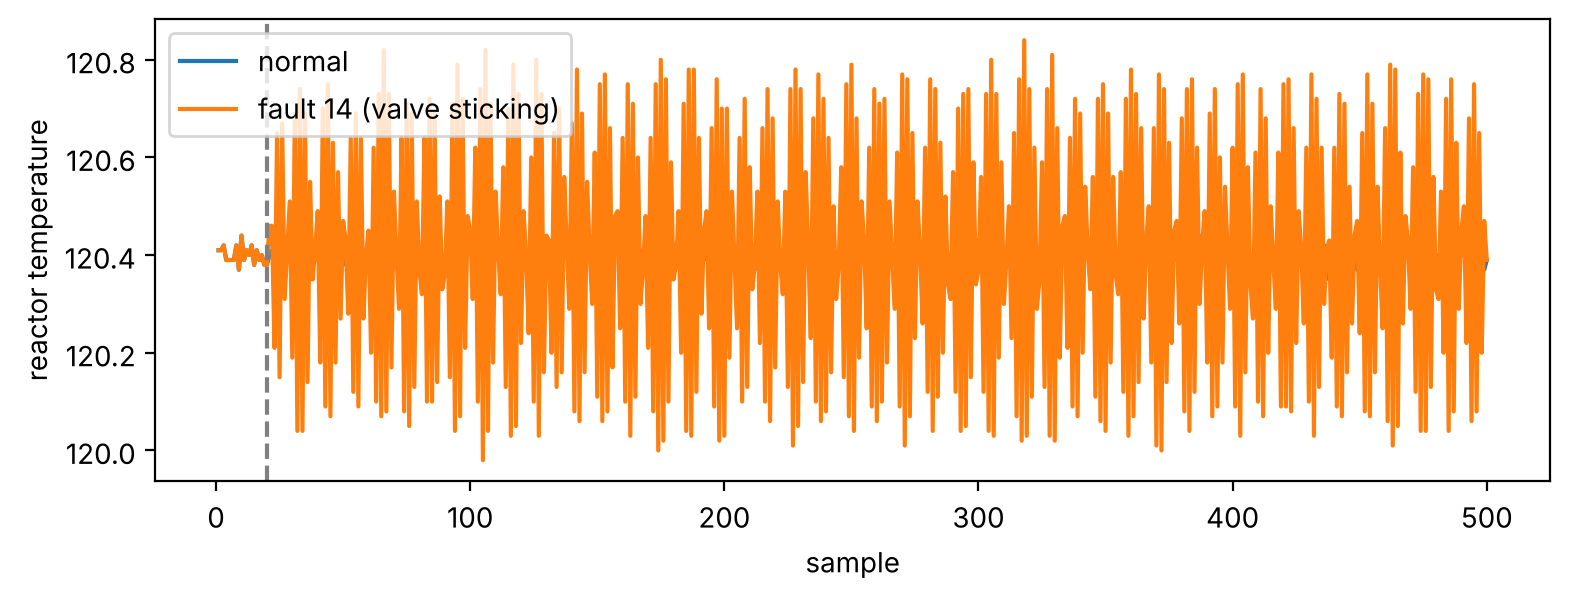

In [4]:
normal_run = df[(df.faultNumber == 0) & (df.simulationRun == 1)]
fault_run = df[(df.faultNumber == 14) & (df.simulationRun == 1)]
plt.figure(figsize=(9, 3))
plt.plot(normal_run["sample"], normal_run["xmeas_9"], label="normal")
plt.plot(fault_run["sample"], fault_run["xmeas_9"], label="fault 14 (valve sticking)")
plt.axvline(20, color="gray", linestyle="--")
plt.xlabel("sample"); plt.ylabel("reactor temperature"); plt.legend(); plt.show()

## 2. Windows and features
- One window = 20 samples = 1 hour. The window moves by 10 samples.
- Each window is described by 3 numbers per variable: **mean, standard deviation, slope** (52 x 3 = 156 features).
- Faults start at sample 20. Windows fully before it are labelled normal. Windows that cross sample 20 are skipped (mixed).

In [5]:
WINDOW, STEP, ONSET = 20, 10, 20
t = np.arange(WINDOW)

features, info = [], []
for (fault, run), g in df.groupby(["faultNumber", "simulationRun"]):
    values = g.sort_values("sample")[sensors].values
    for start in range(0, len(values) - WINDOW + 1, STEP):
        if fault > 0 and start < ONSET < start + WINDOW:
            continue
        w = values[start:start + WINDOW]
        slope = np.polyfit(t, w, 1)[0]
        features.append(np.concatenate([w.mean(0), w.std(0), slope]))
        label = 0 if (fault == 0 or start + WINDOW <= ONSET) else int(fault)
        info.append((label, int(run), start))

X = np.array(features)
info = pd.DataFrame(info, columns=["fault", "run", "start"])
print(X.shape)
info.fault.value_counts().sort_index()

(8660, 156)


fault
0     1140
1      940
2      940
4      940
6      940
11     940
12     940
13     940
14     940
Name: count, dtype: int64

## 3. Train / test split
We split **by run**, not by row. Runs 1-14 are the "history", runs 15-20 are new runs the model has never seen.
(Windows from the same run look very alike, so a random row split would leak information and look too good.)

In [6]:
train = (info.run <= 14).values
test = ~train
scaler = StandardScaler().fit(X[train])
X_train = scaler.transform(X[train])
X_test = scaler.transform(X[test])
y_train = info.fault[train].values
y_test = info.fault[test].values
print(len(y_train), "train windows,", len(y_test), "test windows")

6062 train windows, 2598 test windows


## 4. Baseline A: fault classifier

In [7]:
majority = (y_test == 0).mean()
print("Always guess 'normal':", round(majority, 3))

clf = LogisticRegression(max_iter=2000).fit(X_train, y_train)
pred = clf.predict(X_test)
print("Logistic regression accuracy:", round(accuracy_score(y_test, pred), 3))
print("Logistic regression macro F1:", round(f1_score(y_test, pred, average="macro"), 3))
print(classification_report(y_test, pred))

Always guess 'normal': 0.132


Logistic regression accuracy: 0.977
Logistic regression macro F1: 0.978
              precision    recall  f1-score   support

           0       0.89      0.98      0.93       342
           1       1.00      1.00      1.00       282
           2       1.00      1.00      1.00       282
           4       0.98      1.00      0.99       282
           6       1.00      1.00      1.00       282
          11       1.00      0.93      0.97       282
          12       1.00      0.99      0.99       282
          13       0.96      0.89      0.93       282
          14       1.00      1.00      1.00       282

    accuracy                           0.98      2598
   macro avg       0.98      0.98      0.98      2598
weighted avg       0.98      0.98      0.98      2598



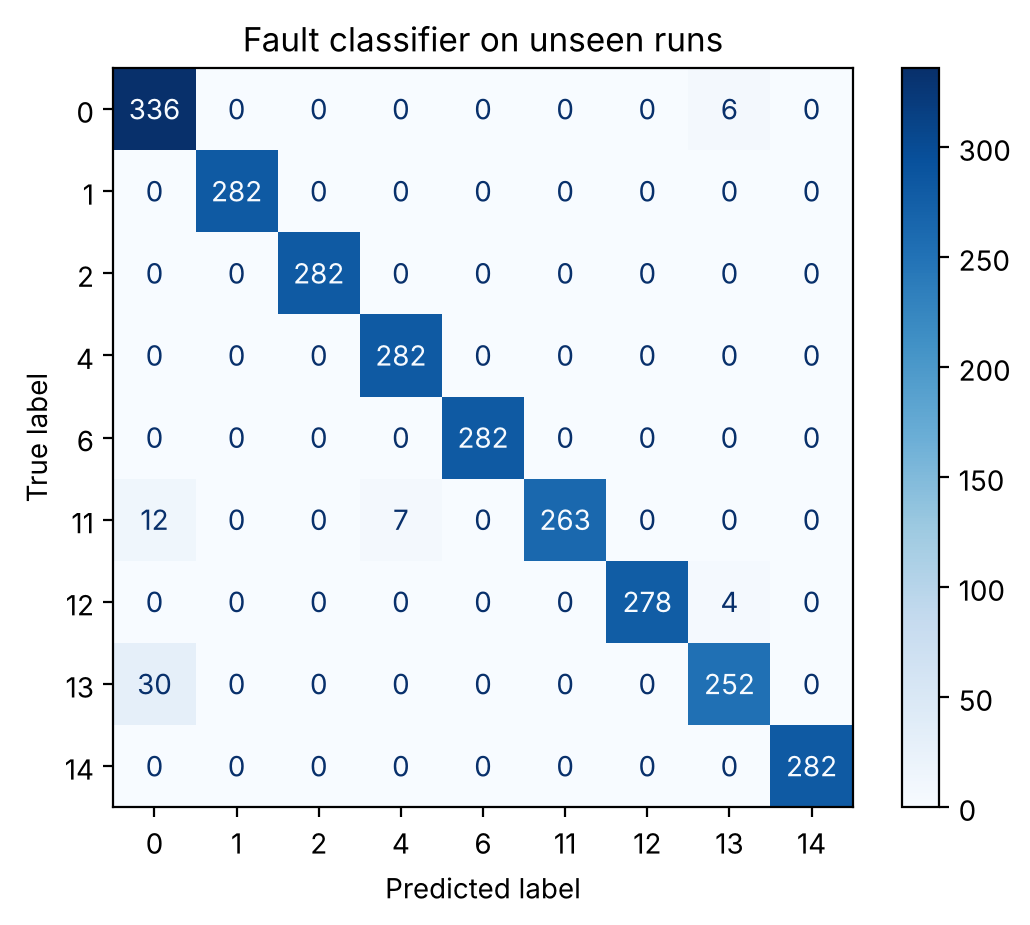

In [8]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=clf.classes_).plot(cmap="Blues")
plt.title("Fault classifier on unseen runs"); plt.show()

## 5. Baseline B: Process Memory (similar past windows)

In [9]:
memory = NearestNeighbors(n_neighbors=5, metric="cosine").fit(X_train)
dist, idx = memory.kneighbors(X_test)
top5 = y_train[idx]

top1 = np.mean(top5[:, 0] == y_test)
hit5 = np.mean([y_test[i] in top5[i] for i in range(len(y_test))])
print("Closest past window has the right fault:", round(top1, 3))
print("Right fault is somewhere in the top 5:  ", round(hit5, 3))

Closest past window has the right fault: 0.914
Right fault is somewhere in the top 5:   0.983


## 6. Notes
- Both baselines are far above the 13% "always normal" guess.
- Most mistakes are fault 13 (slow drift) and fault 11 (random cooling water temperature) being confused with normal. Both are gradual or noisy, so they look normal in the first windows after they start.
- This is simulated data with clear faults, so high scores are expected. Real plant data will be harder.
- The Streamlit app (`app.py`) uses these same two baselines.

## 7. Next steps
- Train a neural network to create the embeddings (instead of mean / std / slope) and compare against these numbers.
- Test on the faults held out of training, with a "nothing similar found" threshold.
- Add retrieval over real instrument and valve documents and connect it to the matched episodes.